Using device: cpu



100%|██████████| 170M/170M [23:34<00:00, 121kB/s]



Dataset downloaded successfully!
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Total training images: 50000
Total testing images: 10000

Training images: 10000
Testing images: 2000


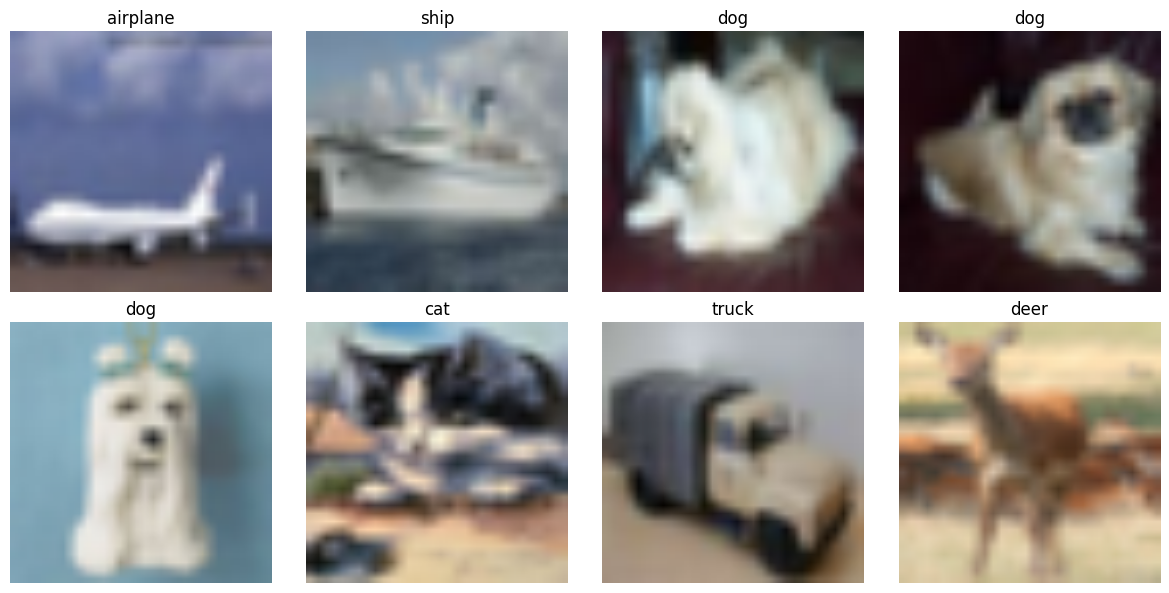


Training Model: AlexNet
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:03<00:00, 79.5MB/s]


AlexNet | Epoch 1/3 | Loss: 0.7495 | Accuracy: 0.7371
AlexNet | Epoch 2/3 | Loss: 0.4467 | Accuracy: 0.8439
AlexNet | Epoch 3/3 | Loss: 0.3316 | Accuracy: 0.8862

 AlexNet Evaluation:
Accuracy: 0.7955
Precision: 0.8041
Recall: 0.7955
F1 Score: 0.7963
Training Time: 955.93 seconds

Training Model: VGG16
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:05<00:00, 101MB/s] 


In [ ]:

# ============================================================
# PRACTICAL 7: TRANSFER LEARNING MODEL COMPARISON
# MODELS: AlexNet, VGG16, ResNet50, EfficientNetB0
# DATASET: CIFAR-10
# TASK: IMAGE CLASSIFICATION
# FRAMEWORK: PYTORCH
# ============================================================


# 1. IMPORT REQUIRED LIBRARIES

import os
import time
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader, Subset
from torchvision import models
from torchvision.models import (
    AlexNet_Weights,
    VGG16_Weights,
    ResNet50_Weights,
    EfficientNet_B0_Weights
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Set random seeds
torch.manual_seed(42)
np.random.seed(42)

# Select GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


# 2. DOWNLOAD CIFAR-10 DATASET

# ImageNet models require 224x224 RGB images
transform = transforms.Compose([

    # Resize images to 224 x 224
    transforms.Resize((224, 224)),

    # Convert images into tensors
    transforms.ToTensor(),

    # Normalize using ImageNet mean and standard deviation
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("\nDownloading CIFAR-10 dataset...")

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

class_names = train_dataset.classes

print("\nDataset downloaded successfully!")
print("Classes:", class_names)
print("Total training images:", len(train_dataset))
print("Total testing images:", len(test_dataset))


# 3. SELECT A STRATIFIED SUBSET FOR EXPERIMENTS

# Use a subset to make four-model comparison practical
# Increase these values to use more images

TRAIN_SAMPLES = 10000
TEST_SAMPLES = 2000

# Select balanced training samples
train_indices, _ = train_test_split(
    np.arange(len(train_dataset)),
    train_size=TRAIN_SAMPLES,
    stratify=train_dataset.targets,
    random_state=42
)

# Select balanced testing samples
test_indices, _ = train_test_split(
    np.arange(len(test_dataset)),
    train_size=TEST_SAMPLES,
    stratify=test_dataset.targets,
    random_state=42
)

# Create subset datasets
train_subset = Subset(train_dataset, train_indices)
test_subset = Subset(test_dataset, test_indices)

# Create data loaders
BATCH_SIZE = 32

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("\nTraining images:", len(train_subset))
print("Testing images:", len(test_subset))


# 4. DISPLAY SAMPLE DATASET IMAGES

images, labels = next(iter(train_loader))

# Undo ImageNet normalization for display
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

plt.figure(figsize=(12, 6))

for i in range(8):

    image = images[i] * std + mean

    image = image.permute(1, 2, 0).numpy()
    image = np.clip(image, 0, 1)

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(class_names[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()


# 5. DEFINE FUNCTION TO LOAD PRE-TRAINED MODELS

def create_model(model_name):

    # Load models with ImageNet-pretrained weights
    if model_name == "AlexNet":

        model = models.alexnet(
            weights=AlexNet_Weights.DEFAULT
        )

        # Replace final classification layer
        model.classifier[6] = nn.Linear(
            model.classifier[6].in_features, 10
        )

        head = model.classifier[6]

    elif model_name == "VGG16":

        model = models.vgg16(
            weights=VGG16_Weights.DEFAULT
        )

        # Replace final classification layer
        model.classifier[6] = nn.Linear(
            model.classifier[6].in_features, 10
        )

        head = model.classifier[6]

    elif model_name == "ResNet50":

        model = models.resnet50(
            weights=ResNet50_Weights.DEFAULT
        )

        # Replace fully connected layer
        model.fc = nn.Linear(
            model.fc.in_features, 10
        )

        head = model.fc

    elif model_name == "EfficientNetB0":

        model = models.efficientnet_b0(
            weights=EfficientNet_B0_Weights.DEFAULT
        )

        # Replace final classification layer
        model.classifier[1] = nn.Linear(
            model.classifier[1].in_features, 10
        )

        head = model.classifier[1]

    # Freeze all pre-trained parameters
    for parameter in model.parameters():
        parameter.requires_grad = False

    # Train only the new classification layer
    for parameter in head.parameters():
        parameter.requires_grad = True

    return model.to(device), head


# 6. DEFINE TRAINING FUNCTION

def train_model(model, head, model_name, epochs=3):

    # Use Cross Entropy loss for multi-class classification
    criterion = nn.CrossEntropyLoss()

    # Optimize only the newly added classification layer
    optimizer = optim.Adam(
        head.parameters(),
        lr=0.001
    )

    history = {
        "train_loss": [],
        "train_accuracy": []
    }

    start_time = time.time()

    for epoch in range(epochs):

        # Keep pretrained feature extractors in evaluation mode
        model.eval()

        # Enable training mode for the classification head
        head.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, targets in train_loader:

            inputs = inputs.to(device)
            targets = targets.to(device)

            # Clear previous gradients
            optimizer.zero_grad()

            # Forward propagation
            outputs = model(inputs)

            # Calculate loss
            loss = criterion(outputs, targets)

            # Backpropagation
            loss.backward()

            # Update classifier weights
            optimizer.step()

            running_loss += loss.item()

            # Get predicted classes
            _, predicted = torch.max(outputs, 1)

            total += targets.size(0)
            correct += (predicted == targets).sum().item()

        # Calculate epoch metrics
        epoch_loss = running_loss / len(train_loader)
        epoch_accuracy = correct / total

        history["train_loss"].append(epoch_loss)
        history["train_accuracy"].append(epoch_accuracy)

        print(
            f"{model_name} | Epoch {epoch + 1}/{epochs} "
            f"| Loss: {epoch_loss:.4f} "
            f"| Accuracy: {epoch_accuracy:.4f}"
        )

    training_time = time.time() - start_time

    return history, training_time


# 7. DEFINE EVALUATION FUNCTION

def evaluate_model(model):

    model.eval()

    actual = []
    predicted = []

    with torch.no_grad():

        for inputs, targets in test_loader:

            inputs = inputs.to(device)

            # Generate predictions
            outputs = model(inputs)

            _, predictions = torch.max(outputs, 1)

            actual.extend(targets.numpy())
            predicted.extend(predictions.cpu().numpy())

    # Calculate evaluation metrics
    accuracy = accuracy_score(actual, predicted)

    precision = precision_score(
        actual, predicted,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        actual, predicted,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        actual, predicted,
        average="weighted",
        zero_division=0
    )

    return actual, predicted, accuracy, precision, recall, f1


# 8. TRAIN AND COMPARE ALL FOUR MODELS

model_names = [
    "AlexNet",
    "VGG16",
    "ResNet50",
    "EfficientNetB0"
]

results = []
histories = {}
all_predictions = {}
trained_heads = {}

EPOCHS = 3

for model_name in model_names:

    print("\n====================================")
    print("Training Model:", model_name)
    print("====================================")

    # Load pre-trained model
    model, head = create_model(model_name)

    # Train model
    history, training_time = train_model(
        model,
        head,
        model_name,
        epochs=EPOCHS
    )

    histories[model_name] = history

    # Evaluate model
    (
        actual,
        predicted,
        accuracy,
        precision,
        recall,
        f1
    ) = evaluate_model(model)

    all_predictions[model_name] = (
        actual,
        predicted
    )

    # Save trained classification head only
    # This avoids storing large duplicate ImageNet weights
    torch.save(
        head.state_dict(),
        model_name.lower() + "_head.pth"
    )

    trained_heads[model_name] = model_name.lower() + "_head.pth"

    # Store performance results
    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Training Time (seconds)": training_time
    })

    print("\n", model_name, "Evaluation:")
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))
    print("Training Time:", round(training_time, 2), "seconds")

    # Release memory before loading next model
    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# 9. DISPLAY MODEL COMPARISON TABLE

comparison_df = pd.DataFrame(results)

print("\n========== MODEL COMPARISON ==========")

print(comparison_df.to_string(index=False))


# 10. VISUALIZE ACCURACY COMPARISON

plt.figure(figsize=(10, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Accuracy"]
)

plt.title("Accuracy Comparison of Pre-trained Models")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(axis="y")

plt.show()


# 11. COMPARE PRECISION, RECALL AND F1 SCORE

comparison_df.set_index("Model")[
    ["Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Performance Comparison of Transfer Learning Models")
plt.xlabel("Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()


# 12. COMPARE TRAINING TIME

plt.figure(figsize=(10, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Training Time (seconds)"]
)

plt.title("Training Time Comparison")
plt.xlabel("Models")
plt.ylabel("Time (Seconds)")
plt.grid(axis="y")

plt.show()


# 13. DISPLAY TRAINING LOSS

plt.figure(figsize=(10, 5))

for model_name in model_names:

    plt.plot(
        histories[model_name]["train_loss"],
        label=model_name
    )

plt.title("Training Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.legend()
plt.grid(True)

plt.show()


# 14. CONFUSION MATRICES FOR ALL MODELS

fig, axes = plt.subplots(2, 2, figsize=(15, 13))

for i, model_name in enumerate(model_names):

    actual, predicted = all_predictions[model_name]

    cm = confusion_matrix(actual, predicted)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=axes[i // 2, i % 2]
    )

    axes[i // 2, i % 2].set_title(
        model_name + " Confusion Matrix"
    )

    axes[i // 2, i % 2].set_xlabel("Predicted Class")
    axes[i // 2, i % 2].set_ylabel("Actual Class")

plt.tight_layout()
plt.show()


# 15. CLASSIFICATION REPORTS

for model_name in model_names:

    actual, predicted = all_predictions[model_name]

    print("\n==========", model_name, "==========")

    print(
        classification_report(
            actual,
            predicted,
            target_names=class_names,
            zero_division=0
        )
    )


# 16. IDENTIFY BEST PERFORMING MODEL

best_model = comparison_df.loc[
    comparison_df["F1 Score"].idxmax()
]

print("\n========== BEST PERFORMING MODEL ==========")

print("Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1 Score:", round(best_model["F1 Score"], 4))


# 17. SAVE COMPARISON RESULTS

comparison_df.to_csv(
    "transfer_learning_comparison.csv",
    index=False
)

# Save prediction results for all models
prediction_data = pd.DataFrame({
    "Actual Class": [
        class_names[i]
        for i in all_predictions["AlexNet"][0]
    ]
})

for model_name in model_names:

    actual, predicted = all_predictions[model_name]

    prediction_data[model_name + " Prediction"] = [
        class_names[i] for i in predicted
    ]

prediction_data.to_csv(
    "transfer_learning_predictions.csv",
    index=False
)

print("\nAll comparison results saved successfully!")


# 18. DOWNLOAD OUTPUT FILES

from google.colab import files

files.download("transfer_learning_comparison.csv")

files.download("transfer_learning_predictions.csv")

for model_name in model_names:

    files.download(
        model_name.lower() + "_head.pth"
    )

print("\nPRACTICAL 7 COMPLETED SUCCESSFULLY!")
